In [69]:
import pandas as pd
import numpy as np
from typing import List, Tuple
from scipy.interpolate import interp1d
from datetime import timedelta
from epiweeks import Week
import epiweeks
from sodapy import Socrata
from datetime import datetime
from datetime import date, timedelta
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
from collections import defaultdict
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

from ensemble import create_ensemble_method1, create_ensemble_method2
from pathlib import Path
import sys

import warnings
warnings.filterwarnings('ignore')

{'client_version': '4.1.25', 'latest_version': '4.1.44', 'event': 'Client version not up to date', 'timestamp': '2026-10-29 16:29:38 -0400'}


In [9]:
def set_date_axis_fmt(ax):
    # Set the locator
    locator = mdates.MonthLocator(interval=2) # every other month
    # Specify the format
    fmt = mdates.DateFormatter('%b %Y')

    X = ax.xaxis
    X.set_major_locator(locator)
    # Specify formatter
    X.set_major_formatter(fmt)

def pull_surveillance_data():
    mapping = {'death':'Deaths', 'case':'Cases', 'hospitalization': 'Hospitalizations'}
    
    url = f"https://raw.githubusercontent.com/cdcepi/FluSight-forecast-hub/main/target-data/target-hospital-admissions.csv"
    return pd.read_csv(url, dtype={'location':str})


In [24]:
all_forecasts = pd.read_parquet('./data/all_forecasts.parquet')
all_forecasts.reference_date.unique()

array(['2025-11-22T00:00:00.000000000', '2025-11-29T00:00:00.000000000',
       '2025-12-06T00:00:00.000000000', '2025-12-13T00:00:00.000000000',
       '2025-12-20T00:00:00.000000000', '2025-12-27T00:00:00.000000000',
       '2026-01-03T00:00:00.000000000', '2026-01-10T00:00:00.000000000',
       '2026-01-17T00:00:00.000000000', '2026-01-24T00:00:00.000000000',
       '2026-01-31T00:00:00.000000000', '2026-02-07T00:00:00.000000000',
       '2026-02-14T00:00:00.000000000', '2026-02-21T00:00:00.000000000',
       '2026-02-28T00:00:00.000000000', '2026-03-07T00:00:00.000000000',
       '2026-03-14T00:00:00.000000000', '2026-03-21T00:00:00.000000000',
       '2026-03-28T00:00:00.000000000', '2026-04-04T00:00:00.000000000',
       '2026-04-11T00:00:00.000000000', '2026-04-18T00:00:00.000000000',
       '2026-04-25T00:00:00.000000000', '2026-05-02T00:00:00.000000000',
       '2026-05-09T00:00:00.000000000', '2026-05-16T00:00:00.000000000',
       '2026-05-23T00:00:00.000000000', '2026-05-30

In [7]:
ens = pd.read_parquet('./data/ensemble_forecasts.pq')
ens

,reference_date,location,horizon,target,target_end_date,output_type,output_type_id,value,model
0,2025-11-22,01,0.0,wk inc flu hosp,2025-11-22,quantile,0.01,9.000000,Median Epistorm Ensemble
1,2025-11-22,01,0.0,wk inc flu hosp,2025-11-22,quantile,0.025,11.000000,Median Epistorm Ensemble
2,2025-11-22,01,0.0,wk inc flu hosp,2025-11-22,quantile,0.05,13.000000,Median Epistorm Ensemble
3,2025-11-22,01,0.0,wk inc flu hosp,2025-11-22,quantile,0.1,16.000000,Median Epistorm Ensemble
4,2025-11-22,01,0.0,wk inc flu hosp,2025-11-22,quantile,0.15,18.000000,Median Epistorm Ensemble
...,...,...,...,...,...,...,...,...,...
333574,2026-05-30,US,3.0,wk inc flu hosp,2026-06-20,quantile,0.85,1501.595962,LOP Epistorm Ensemble
333575,2026-05-30,US,3.0,wk inc flu hosp,2026-06-20,quantile,0.9,1907.140607,LOP Epistorm Ensemble
333576,2026-05-30,US,3.0,wk inc flu hosp,2026-06-20,quantile,0.95,4115.826511,LOP Epistorm Ensemble
333577,2026-05-30,US,3.0,wk inc flu hosp,2026-06-20,quantile,0.975,8099.706841,LOP Epistorm Ensemble


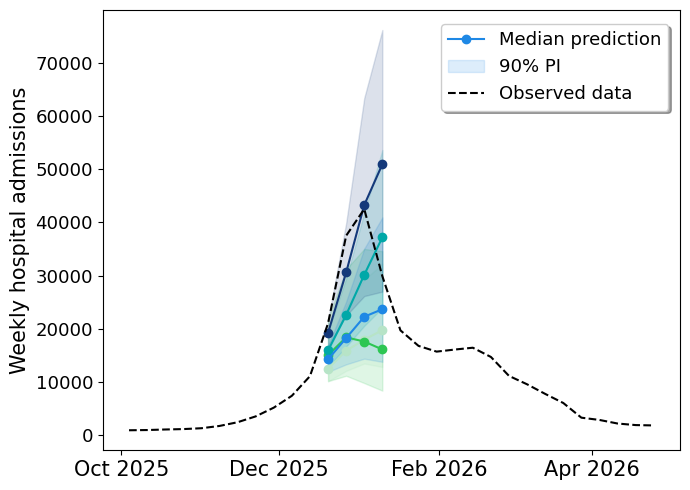

In [112]:
location = 'US'
date = '2025-12-20'
models = preds.model.unique()[4:10]

colors = [
    "#B7E4C7",  # Light Mint Green
    "#2DC653",  # Vivid Green
    "#00A8A8",  # Bright Teal
    "#1E88E5",  # Strong Blue
    "#14397A",  # Dark Navy
]

surv = pull_surveillance_data()

locations = pd.read_csv('./locations.csv')
#locations['location'] = locations['location'].apply(lambda x: '0' + x if x!='US' and int(x)<10 else x)
surv = surv.merge(locations)

preds = pd.read_parquet('./data/all_forecasts.parquet')

preds = preds.merge(locations)
preds = preds.sort_values(by='location_name')

preds = preds[(preds.location==location) & (preds.reference_date == date)]

preds = preds[preds.model!='FluSight-ensemble']

fig, ax = plt.subplots(1,1,figsize = (7,5))

#fig.suptitle(f"Weekly Flu Hospitalizations as of {reference_date}", fontsize = 22, y = .995)

#(0.01,0.99),(0.05,0.95),
intervals = [(0.05,0.95)]
map_alpha = lambda interval_range: 0.5 * (1-interval_range) + 0.1
color = 'seagreen'

r = 0
c = 0


i=0
for model in models:

    predictions = preds[(preds.location==location) & (preds.horizon>=0) &\
                                (preds.target == 'wk inc flu hosp') & (preds.model==model)]

    predictions['output_type_id'] = predictions['output_type_id'].astype(float)

    t = predictions.target_end_date.unique()
    predictions['target_end_date'] = pd.to_datetime(predictions['target_end_date'])
    predictions = predictions.sort_values(by='target_end_date')
    #intervals
    for interval in intervals:
        q_low,q_upp = interval
        interval_range = q_upp - q_low
        alpha = map_alpha(interval_range)
        pred_low = predictions[predictions['output_type_id']==q_low]['value']
        pred_upp = predictions[predictions['output_type_id']==q_upp]['value']
        ax.fill_between(predictions.target_end_date.unique(),pred_upp,pred_low, color=colors[i], alpha=alpha,
                            label=fr"{int(round(interval_range*100))}% PI")

    pred_point = predictions[predictions['output_type_id']==.5]['value']
    if len(pred_point) > 0:
        ax.plot(predictions.target_end_date.unique(),pred_point,'-o',color=colors[i], label='Median prediction')


        set_date_axis_fmt(ax)

        #ax.set_title(locations[locations.location==location].location_name.unique()[0], fontsize=12)    

       # ax.text(0.25, 0.85, f"models = {model_counts.loc[model_counts['location']==loc, 'num_models'].values[0]}",
        #    transform=ax.transAxes, va='top', ha='left', fontsize=11)

        if c==0:
            ax.set_ylabel('Weekly hospital admissions', fontsize=15)
            
    i+=1
    
surv['date'] = pd.to_datetime(surv['date'])

surv = surv.sort_values(by=['location_name','date'])

d = surv[(surv.location==location) & (surv.date>=pd.to_datetime('2025-10-01')) &\
         (surv.date<pd.to_datetime('2026-05-01'))]
ax.plot(d.date,d['value'],'--',color='k',label='Observed data')

plt.xticks(fontsize=15)
plt.yticks(fontsize=13)

handles, labels = ax.get_legend_handles_labels()
order = [7,6,10]
fig.legend([handles[idx] for idx in order], [labels[idx] for idx in order],fontsize=13,  
           fancybox=True, shadow=True,bbox_to_anchor=(0.975, .96), )
 


plt.tight_layout()
#plt.savefig(f'./submissions_26-27/figs/{modelname}_{reference_date}_hosp_quantile.pdf')
plt.show()

In [72]:
predsfilt = preds[preds.model.isin(models)]

In [75]:
medens = create_ensemble_method1(predsfilt)
medens = medens[medens.horizon>=0]

medens

,reference_date,location,horizon,target,target_end_date,output_type,output_type_id,value
23,2025-12-20,US,0.0,wk inc flu hosp,2025-12-20,quantile,0.01,11642.00000
24,2025-12-20,US,0.0,wk inc flu hosp,2025-12-20,quantile,0.025,11753.00000
25,2025-12-20,US,0.0,wk inc flu hosp,2025-12-20,quantile,0.05,11938.00000
26,2025-12-20,US,0.0,wk inc flu hosp,2025-12-20,quantile,0.1,12292.00000
27,2025-12-20,US,0.0,wk inc flu hosp,2025-12-20,quantile,0.15,12591.00000
...,...,...,...,...,...,...,...,...
110,2025-12-20,US,3.0,wk inc flu hosp,2026-01-10,quantile,0.85,33883.00000
111,2025-12-20,US,3.0,wk inc flu hosp,2026-01-10,quantile,0.9,36848.00000
112,2025-12-20,US,3.0,wk inc flu hosp,2026-01-10,quantile,0.95,40935.00000
113,2025-12-20,US,3.0,wk inc flu hosp,2026-01-10,quantile,0.975,42596.00000


In [81]:
lopens = create_ensemble_method2(predsfilt)
lopens = lopens[lopens.horizon>=0]

lopens

,output_type_id,value,horizon,target_end_date,location,reference_date,model,output_type,target
0,0.01,8849.397261,0.0,2025-12-20,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp
1,0.025,10123.251078,0.0,2025-12-20,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp
2,0.05,10859.786278,0.0,2025-12-20,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp
3,0.1,11703.343172,0.0,2025-12-20,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp
4,0.15,12264.793233,0.0,2025-12-20,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp
...,...,...,...,...,...,...,...,...,...
87,0.85,48201.172667,3.0,2026-01-10,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp
88,0.9,53929.000990,3.0,2026-01-10,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp
89,0.95,63087.000000,3.0,2026-01-10,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp
90,0.975,73121.300000,3.0,2026-01-10,US,2025-12-20,LOP Epistorm Ensemble,quantile,wk inc flu hosp


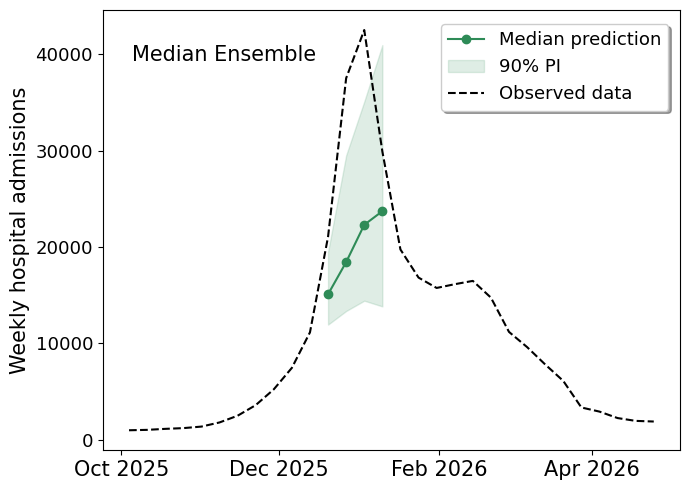

In [120]:
fig, ax = plt.subplots(1,1,figsize = (7,5))

#fig.suptitle(f"Weekly Flu Hospitalizations as of {reference_date}", fontsize = 22, y = .995)

#(0.01,0.99),(0.05,0.95),
intervals = [(0.05,0.95)]
map_alpha = lambda interval_range: 0.5 * (1-interval_range) + 0.1
color = 'seagreen'

r = 0
c = 0


i=0


predictions = medens.copy()

predictions['output_type_id'] = predictions['output_type_id'].astype(float)

t = predictions.target_end_date.unique()
predictions['target_end_date'] = pd.to_datetime(predictions['target_end_date'])
predictions = predictions.sort_values(by='target_end_date')
#intervals
for interval in intervals:
    q_low,q_upp = interval
    interval_range = q_upp - q_low
    alpha = map_alpha(interval_range)
    pred_low = predictions[predictions['output_type_id']==q_low]['value']
    pred_upp = predictions[predictions['output_type_id']==q_upp]['value']
    ax.fill_between(predictions.target_end_date.unique(),pred_upp,pred_low, color=color, alpha=alpha,
                        label=fr"{int(round(interval_range*100))}% PI")

pred_point = predictions[predictions['output_type_id']==.5]['value']
if len(pred_point) > 0:
    ax.plot(predictions.target_end_date.unique(),pred_point,'-o',color=color, label = 'Median prediction')


    set_date_axis_fmt(ax)

    #ax.set_title(locations[locations.location==location].location_name.unique()[0], fontsize=12)    

    ax.text(0.05, 0.92, f"Median Ensemble",
        transform=ax.transAxes, va='top', ha='left', fontsize=15)
 

    if c==0:
        ax.set_ylabel('Weekly hospital admissions', fontsize=15)

i+=1

surv['date'] = pd.to_datetime(surv['date'])

surv = surv.sort_values(by=['location_name','date'])

d = surv[(surv.location==location) & (surv.date>=pd.to_datetime('2025-10-01')) &\
     (surv.date<pd.to_datetime('2026-05-01'))]
ax.plot(d.date,d['value'],'--',color='k',label='Observed data')

plt.xticks(fontsize=15)
plt.yticks(fontsize=13)

handles, labels = ax.get_legend_handles_labels()
order = [1,0,2]
fig.legend([handles[idx] for idx in order], [labels[idx] for idx in order],fontsize=13,  
           fancybox=True, shadow=True,bbox_to_anchor=(0.975, .96), )


plt.tight_layout()
#plt.savefig(f'./submissions_26-27/figs/{modelname}_{reference_date}_hosp_quantile.pdf')
plt.show()

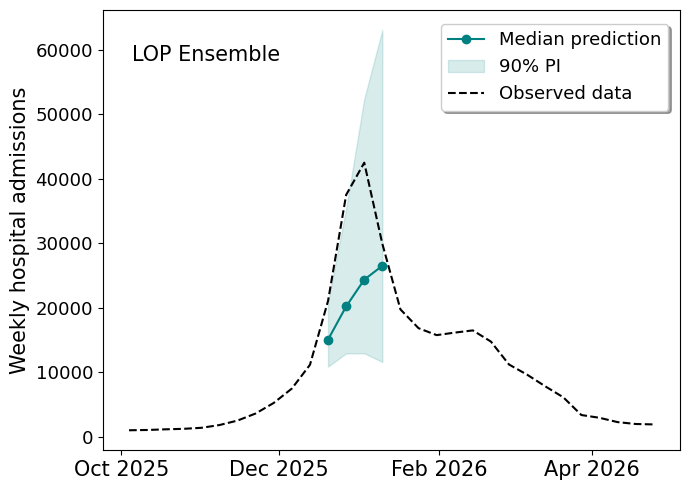

In [119]:
fig, ax = plt.subplots(1,1,figsize = (7,5))

#fig.suptitle(f"Weekly Flu Hospitalizations as of {reference_date}", fontsize = 22, y = .995)

#(0.01,0.99),(0.05,0.95),
intervals = [(0.05,0.95)]
map_alpha = lambda interval_range: 0.5 * (1-interval_range) + 0.1
color = 'teal'

r = 0
c = 0


i=0


predictions = lopens.copy()

predictions['output_type_id'] = predictions['output_type_id'].astype(float)

t = predictions.target_end_date.unique()
predictions['target_end_date'] = pd.to_datetime(predictions['target_end_date'])
predictions = predictions.sort_values(by='target_end_date')
#intervals
for interval in intervals:
    q_low,q_upp = interval
    interval_range = q_upp - q_low
    alpha = map_alpha(interval_range)
    pred_low = predictions[predictions['output_type_id']==q_low]['value']
    pred_upp = predictions[predictions['output_type_id']==q_upp]['value']
    ax.fill_between(predictions.target_end_date.unique(),pred_upp,pred_low, color=color, alpha=alpha,
                        label=fr"{int(round(interval_range*100))}% PI")

pred_point = predictions[predictions['output_type_id']==.5]['value']
if len(pred_point) > 0:
    ax.plot(predictions.target_end_date.unique(),pred_point,'-o',color=color, label = 'Median prediction')


    set_date_axis_fmt(ax)

    #ax.set_title(locations[locations.location==location].location_name.unique()[0], fontsize=12)    

    ax.text(0.05, 0.92, f"LOP Ensemble",
        transform=ax.transAxes, va='top', ha='left', fontsize=15)

    if c==0:
        ax.set_ylabel('Weekly hospital admissions', fontsize=15)

i+=1

surv['date'] = pd.to_datetime(surv['date'])

surv = surv.sort_values(by=['location_name','date'])

d = surv[(surv.location==location) & (surv.date>=pd.to_datetime('2025-10-01')) &\
     (surv.date<pd.to_datetime('2026-05-01'))]
ax.plot(d.date,d['value'],'--',color='k',label='Observed data')

plt.xticks(fontsize=15)
plt.yticks(fontsize=13)

handles, labels = ax.get_legend_handles_labels()
order = [1,0,2]
fig.legend([handles[idx] for idx in order], [labels[idx] for idx in order],fontsize=13,  
           fancybox=True, shadow=True,bbox_to_anchor=(0.975, .96), )


plt.tight_layout()
#plt.savefig(f'./submissions_26-27/figs/{modelname}_{reference_date}_hosp_quantile.pdf')
plt.show()

In [ ]:
# all together:

In [127]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ---- assumes these already exist in your session ----
# preds (filtered to location/date, no FluSight-ensemble), surv, medens, lopens,
# models, colors, location, set_date_axis_fmt

q_low, q_upp = 0.05, 0.95
fill_alpha = 0.5 * (1 - (q_upp - q_low)) + 0.1   # same as your map_alpha


def prep(df):
    df = df.copy()
    df['output_type_id'] = df['output_type_id'].astype(float)
    df['target_end_date'] = pd.to_datetime(df['target_end_date'])
    return df.sort_values('target_end_date')


def draw_forecast(ax, df, color, label=None, alpha_scale=1.0):
    """Draw 90% PI + median. Returns the artists so they can be faded later."""
    df = prep(df)
    dates = df.target_end_date.unique()
    lo = df[df.output_type_id == q_low]['value'].values
    hi = df[df.output_type_id == q_upp]['value'].values
    med = df[df.output_type_id == 0.5]['value'].values
    artists = []
    artists.append(ax.fill_between(dates, hi, lo, color=color,
                                   alpha=fill_alpha * alpha_scale, lw=0))
    if len(med) > 0:
        artists.append(ax.plot(dates, med, '-o', color=color, label=label, ms=4)[0])
    return artists


# ---------------- figure ----------------
fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Observed data
surv['date'] = pd.to_datetime(surv['date'])
d = surv[(surv.location == location) &
         (surv.date >= '2025-10-01') & (surv.date < '2026-05-01')].sort_values('date')
for ax in (axL, axR):
    ax.plot(d.date, d['value'], '--', color='k', lw=1.5)

# LEFT: all models (static)
for i, model in enumerate(models):
    p = preds[(preds.location == location) & (preds.horizon >= 0) &
              (preds.target == 'wk inc flu hosp') & (preds.model == model)]
    if len(p) == 0:
        continue
    draw_forecast(axL, p, colors[i % len(colors)], label=model)  # cycles if >5 models

axL.set_ylabel('Weekly hospital admissions', fontsize=15)
axL.text(0.05, 0.92, 'Individual Models', transform=axL.transAxes,
         va='top', ha='left', fontsize=15)

# RIGHT: both ensembles drawn once; we just fade their alpha
med_color, lop_color = 'seagreen', 'teal'
med_art = draw_forecast(axR, medens, med_color)
lop_art = draw_forecast(axR, lopens, lop_color)

med_txt = axR.text(0.05, 0.92, 'Median Ensemble', transform=axR.transAxes,
                   va='top', ha='left', fontsize=15, color=med_color)
lop_txt = axR.text(0.05, 0.92, 'LOP Ensemble', transform=axR.transAxes,
                   va='top', ha='left', fontsize=15, color=lop_color)

legend_handles = [Line2D([0], [0], color='gray', marker='o', label='Median prediction'),
                  Patch(color='gray', alpha=0.3, label='90% PI'),
                  Line2D([0], [0], color='k', ls='--', label='Observed data')]
for ax in (axL, axR):
    ax.legend(handles=legend_handles, fontsize=13, loc='upper right',
              fancybox=True, shadow=True)

for ax in (axL, axR):
    set_date_axis_fmt(ax)
    ax.tick_params(axis='x', labelsize=15)
    ax.tick_params(axis='y', labelsize=13)

plt.tight_layout()


# ---------------- animation ----------------
def set_group(artists, text, w):
    """w in [0,1] = visibility of this ensemble."""
    artists[0].set_alpha(fill_alpha * w)       # PI band
    for a in artists[1:]:
        a.set_alpha(w)                         # median line
    text.set_alpha(w)


HOLD, FADE = 20, 8   # frames to hold each view / frames to crossfade
# weight of the Median view over time: hold -> fade out -> hold(0) -> fade in
w_med = np.concatenate([np.ones(HOLD),
                        np.linspace(1, 0, FADE),
                        np.zeros(HOLD),
                        np.linspace(0, 1, FADE)])


def update(f):
    w = w_med[f]
    set_group(med_art, med_txt, w)
    set_group(lop_art, lop_txt, 1 - w)
    return med_art + lop_art + [med_txt, lop_txt]


ani = FuncAnimation(fig, update, frames=len(w_med), interval=80, blit=False)
ani.save('ensemble_swap.gif', writer=PillowWriter(fps=12), dpi=120)
plt.close(fig)
print('saved ensemble_swap.gif')

# Optional: preview in a notebook
# from IPython.display import Image; Image('ensemble_swap.gif')

saved ensemble_swap.gif


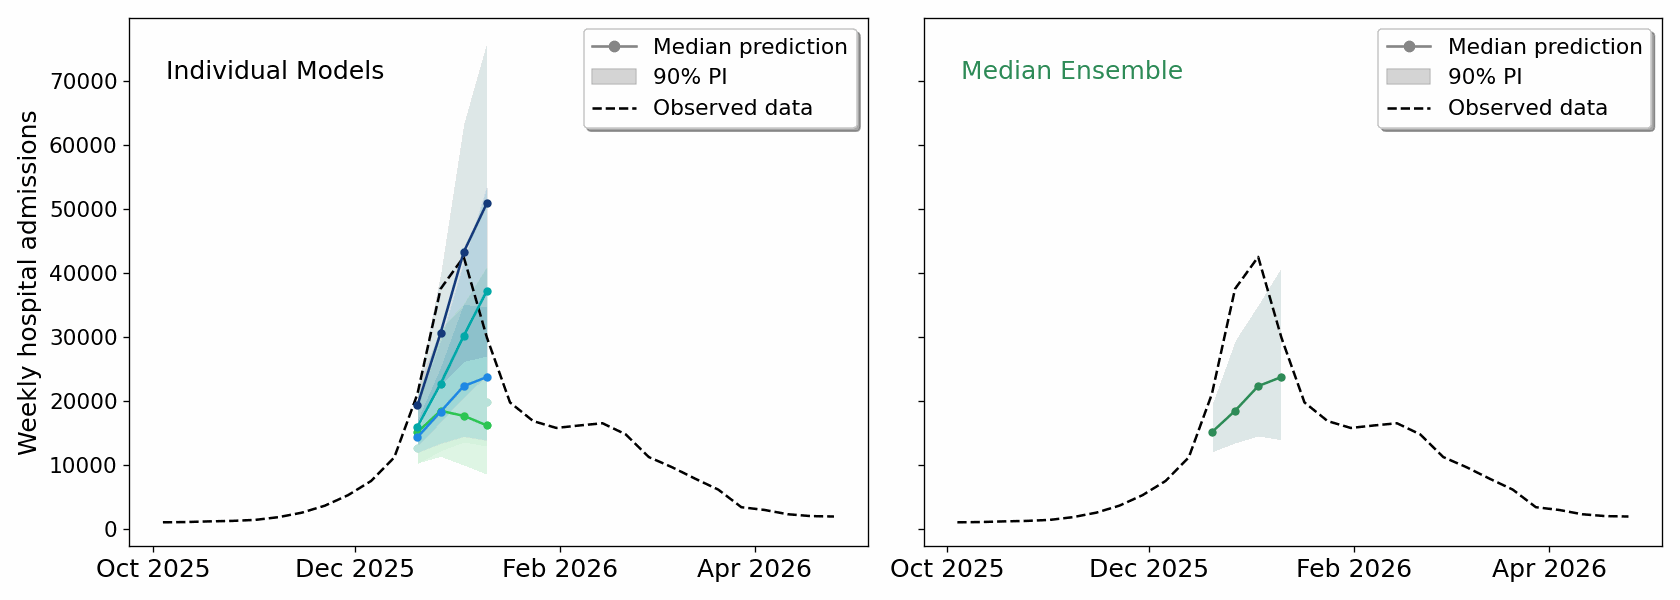

In [128]:
from IPython.display import Image; Image('ensemble_swap.gif')